In [11]:
from collections import Counter
import screed
import pandas as pd
import matplotlib.pyplot as plt
import re

def reverse_complement(dna_seq):
    """ 
    Return the reverse complement of a DNA sequence. 
    Arguments:
        dna_seq - DNA input sequence as a string
        
    Returns:
        reverse_complement - Reverse complement of DNA input sequence 
    
    """
    complement = {'a': 't', 'A':'T', 't': 'a', 'T':'A','c': 'g','C':'G', 'g': 'c', 'G':'C'}
    
    reverse_complement_seq = ''.join(complement.get(base, base) for base in reversed(dna_seq))
        
    return reverse_complement_seq

def translate(dna_seq):
    """
    Generates a protein sequence from a DNA sequence inputted as a string. It will only convert if the exon is in upper
    case

    Arguments:
        dna_seq(str) - input DNA sequence
        
    Returns:
        protein_sequence(str) - output protein sequence 
    """
    
    #Generate dictionary of codons for dna to protein translation
    
    codon_table = {
    'GCT': 'A', 'GCC': 'A', 'GCA': 'A', 'GCG': 'A',  # Alanine
    'TGT': 'C', 'TGC': 'C',                          # Cysteine
    'GAT': 'D', 'GAC': 'D',                          # Aspartic acid
    'GAA': 'E', 'GAG': 'E',                          # Glutamic acid
    'TTT': 'F', 'TTC': 'F',                          # Phenylalanine
    'GGT': 'G', 'GGC': 'G', 'GGA': 'G', 'GGG': 'G',  # Glycine
    'CAT': 'H', 'CAC': 'H',                          # Histidine
    'ATT': 'I', 'ATC': 'I', 'ATA': 'I',              # Isoleucine
    'AAA': 'K', 'AAG': 'K',                          # Lysine
    'TTA': 'L', 'TTG': 'L', 'CTT': 'L', 'CTC': 'L', 'CTA': 'L', 'CTG': 'L',  # Leucine
    'ATG': 'M',                                      # Methionine (Start codon)
    'AAT': 'N', 'AAC': 'N',                          # Asparagine
    'CCT': 'P', 'CCC': 'P', 'CCA': 'P', 'CCG': 'P',  # Proline
    'CAA': 'Q', 'CAG': 'Q',                          # Glutamine
    'CGT': 'R', 'CGC': 'R', 'CGA': 'R', 'CGG': 'R', 'AGA': 'R', 'AGG': 'R',  # Arginine
    'TCT': 'S', 'TCC': 'S', 'TCA': 'S', 'TCG': 'S', 'AGT': 'S', 'AGC': 'S',  # Serine
    'ACT': 'T', 'ACC': 'T', 'ACA': 'T', 'ACG': 'T',  # Threonine
    'GTT': 'V', 'GTC': 'V', 'GTA': 'V', 'GTG': 'V',  # Valine
    'TGG': 'W',                                      # Tryptophan
    'TAT': 'Y', 'TAC': 'Y',                          # Tyrosine
    'TAA': '*', 'TAG': '*', 'TGA': '*'               # Stop codons
    }
    
    # Initialize the protein sequence
    protein = ""

    # Iterate over the DNA sequence in steps of 3 (codon length)
    for i in range(0, len(dna_seq) - len(dna_seq) % 3, 3):
        
        # Define a codon as 3 bases
        codon = dna_seq[i:i + 3]
        # Translate the codon into an amino acid based on the dictionary
        if codon.isupper():
            protein += codon_table.get(codon, '?')  # '?' is a placeholder for unknown codons
        else:
            protein += 'x'

    return protein

In [12]:
#Insert all variants details for CORe analysis below.

fastq_file = r"C:\Users\dasak\OneDrive\Desktop\Miseq_pilot\Pilot_rep1\pre_S4_L001_R1_001.fastq.gz" #Insert path to fastq file below 
output_name = 'O00571_326' # Name of output file, will be saved as .test in the same directory as this notebook. Do not include .csv in the name, it will be added automatically.
sequencing_strand = 'Reverse' # Indicate whether the sequencing strand is 'Forward' or 'Reverse'
wt_codon = 'CGA' # Insert the wild type codon in the format 'AAA' (3 nucleotides, no spaces)
wt_amino_acid = translate(wt_codon) # Insert the wild type amino acid in the format 'A' (1 letter code, no spaces)    
variant_codon = 'CAT' # Insert the codon of interest in the format 'AAA' (3 nucleotides, no spaces)
variant_amino_acid = translate(variant_codon) # Insert the amino acid of interest in the format 'A' (1 letter code, no spaces)
isp_primer = '' # Insert the ISP primer sequence for off-target checks in the format 'AAA' (nucleotides, no spaces). If not available, leave as an empty string ''.
isp_primer = isp_primer.strip().upper() # Convert ISP primer sequence to uppercase
#prefix of desired amplicon up to codon of interest
prefix ="aaacaaaacaaaacaaaaaaacaaaaacaaaataaaacatacttgcaaaagtctaatccaattttgccccgctccatcatgtcgaccaa"
prefix = prefix.strip().upper()
#suffix of desired amplicon from codon of interest to end of read length
suffix = "gccaggtgtagcaactagaagatggcatccacgttcca" 
suffix = suffix.strip().upper()

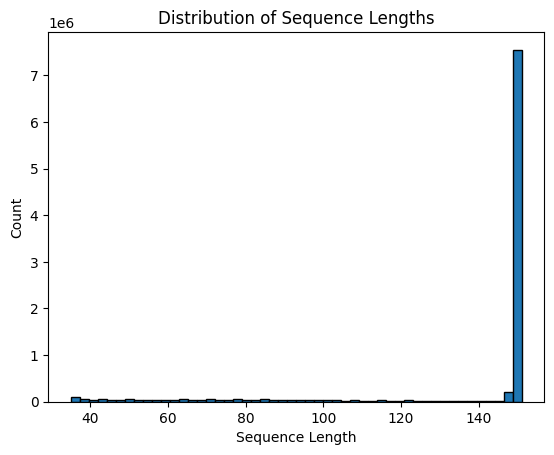

In [13]:
# screed.open handles .gz automatically and iterates efficiently
lengths = [len(record.sequence) for record in screed.open(fastq_file)]

# Plot histogram
plt.hist(lengths, bins=50, edgecolor="black")
plt.xlabel("Sequence Length")
plt.ylabel("Count")
plt.title("Distribution of Sequence Lengths")
plt.show()

In [14]:
seq_counter = Counter()

# screed handles gzip automatically and is very fast
with screed.open(fastq_file) as seqfile:
    for record in seqfile:
        seq_counter[record.sequence] += 1

for seq, count in seq_counter.most_common(1000):
    print(f"{seq} : {count}")

GATCGGAAGAGCACACGTCTGAACTCCAGTCACTAGGAGCTATCTGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG : 287098
GATCGGAAGAGCACACGTCTGAACTCCAGTCACTAGGAGCTATCTGGGGGGGGGGGGGGGGGGGGGTTAAACGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG : 104444
GATCGGAAGAGCACACGTCTGAACTCCAGTCACTAGGAGCTATCTGGGGGGGGGGGGGGGGGGGGGTTTAACGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG : 84385
GATCGGAAGAGCACACGTCTGAACTCCAGTCACTAGGAGCTATCTGGGGTGGGGGGGTGTGGGTGTTTAAACGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG : 77232
GATCGGAAGAGCACACGTCTGAACTCCAGTCACTAGGAGCTATCTGGGGGGGGGGGGTGTGGGTGTTAAAAAAGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG : 52497
GATCGGAAGAGCACACGTCTGAACTCCAGTCACTAGGAGCTATCTGGGGGGGGGGGGGGGGGGGGGTTTAAGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG : 49845
NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN : 

In [ ]:
# Define the codon to label mapping, including the variant codon if provided. 
# Make sure that the codon library is correct for the organism you are working in.
codon_to_label = {
        'GCC': 'A', 'TGC': 'C', 'GAC': 'D', 'GAG': 'E', 'TTC': 'F', 
        'GGC': 'G', 'CAC': 'H', 'ATC': 'I', 'AAG': 'K', 'CTG': 'L', 
        'ATG': 'M', 'AAC': 'N', 'CCC': 'P', 'CAG': 'Q', 'CGG': 'R', 
        'AGC': 'S', 'ACC': 'T', 'GTG': 'V', 'TGG': 'W', 'TAC': 'Y', 
        'TAA': 'Stop', 
        variant_codon: f'Patient Variant ({variant_codon}/{variant_amino_acid})',    
    }

# Create regex to capture the 3-base variant
# This looks for the prefix, captures any 3 bases, and then the suffix
extract_pattern = re.compile(rf"{prefix}([ATCG]{{3}}){suffix}")
if isp_primer:
    isp_primer_pattern = re.compile(isp_primer)

counts = Counter()
total_reads = 0
all_variants_count = 0
isp_primer_count = 0

for record in screed.open(fastq_file):
    total_reads += 1
    seq = record.sequence
    if isp_primer:
        if isp_primer_pattern.search(seq):
            isp_primer_count += 1
    match = extract_pattern.search(seq)
    if match:
        all_variants_count += 1
        codon = match.group(1) # The [ATCG]{3} part
        if sequencing_strand == 'Reverse':
            codon = reverse_complement(codon)
        if codon in codon_to_label:
            label = codon_to_label[codon]
            counts[label] += 1

final_data = {
    "reads": total_reads,
    "codons": all_variants_count,
    "isp_primer_count": isp_primer_count
    }
for label in codon_to_label.values():
    final_data[label] = counts.get(label, 0)


df = pd.DataFrame(list(final_data.items()), columns=["Label", "Counts"])
df.loc[df['Label'] == wt_amino_acid, 'Label'] = f'{wt_amino_acid} (WT)'
df['Name'] = output_name # Add a 'Name' column that's the same as 'Label'
display(df)
df.to_excel ('test_folder/' + output_name + '.xlsx', index=False)

,Label,Counts,Name
0,reads,9370072,O00571_326
1,codons,2337,O00571_326
2,isp_primer_count,0,O00571_326
3,A,92,O00571_326
4,C,127,O00571_326
5,D,126,O00571_326
6,E,105,O00571_326
7,F,107,O00571_326
8,G,89,O00571_326
9,H,116,O00571_326
